<a href="https://colab.research.google.com/github/Desire-in-tech/traffic-sign-detection/blob/task-08%2Fgtsdb-yolov8-foundation/notebooks/task_08_traffic_sign_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 8 — Full-Scene Traffic Sign Detection with YOLOv8

**Project:** German Traffic Sign Detection Benchmark (GTSDB)  
**Workflow:** dataset audit → annotation conversion → leakage-safe split → training → evaluation → speed benchmark → ONNX → recorded-video inference.

This is the complete working notebook. Run cells from top to bottom. Some cells deliberately stop with a clear message if the dataset mirror has a different layout or annotation format; inspect the printed audit and adjust the clearly marked configuration rather than guessing. Training metrics are generated only by running the model.

**Important:** this project performs object detection on full road-scene images (bounding boxes + class labels), not cropped-image classification. Raw data, weights and generated videos stay in Google Drive, not GitHub.

## 0. Runtime and project configuration

In Colab choose **Runtime → Change runtime type → T4 GPU** if available. CPU is supported for debugging but training will be much slower. This notebook uses a Google Drive workspace so data and checkpoints survive Colab sessions.

In [7]:
from pathlib import Path
import os, sys, json, random, shutil, zipfile, subprocess, textwrap, time, platform
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/traffic-sign-detection")
DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
RUNS_DIR = PROJECT_DIR / "runs"
EXPORT_DIR = PROJECT_DIR / "exports"
VIDEO_DIR = PROJECT_DIR / "videos"
for p in [RAW_DIR, PROCESSED_DIR, RUNS_DIR, EXPORT_DIR, VIDEO_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("Project workspace:", PROJECT_DIR)
print("Python:", sys.version)
print("Platform:", platform.platform())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project workspace: /content/drive/MyDrive/traffic-sign-detection
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39


## 1. Install dependencies and check hardware

Keep pandas and Pillow compatible with the current Colab image. The notebook pins these two packages to avoid the resolver conflicts reported by Colab, Dask/CUDF and Gradio. If Colab asks for a runtime restart after installation, restart once and rerun from the top.

In [8]:
%pip -q install -U "ultralytics>=8.3,<9" opencv-python-headless "pandas==2.2.3" pyyaml "pillow<13" matplotlib seaborn scikit-learn onnx onnxruntime kaggle

import torch, cv2, ultralytics
import pandas as pd
import PIL
from ultralytics import YOLO
print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("OpenCV:", cv2.__version__)
print("pandas:", pd.__version__)
print("Pillow:", PIL.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU unavailable. You can continue for data preparation, but consider enabling a Colab GPU before training.")

Ultralytics: 8.4.213
PyTorch: 2.14.1+cu130
OpenCV: 4.14.0
pandas: 2.2.3
Pillow: 11.3.0
CUDA available: True
GPU: Tesla T4


## 2. Download the dataset

Default Kaggle dataset: `safabouguezzi/german-traffic-sign-detection-benchmark-gtsdb`.

Create a Kaggle API token in your Kaggle account (Settings → API → Create New Token), then upload the downloaded `kaggle.json` when prompted. The token is copied directly into the Colab runtime with restrictive permissions. **Never paste it into this notebook, GitHub, or this chat.**

If you already have the official GTSDB archive, set `USE_KAGGLE = False` and upload/extract it into `data/raw`.

In [9]:
USE_KAGGLE = True
KAGGLE_DATASET = "safabouguezzi/german-traffic-sign-detection-benchmark-gtsdb"
if USE_KAGGLE:
    download_dir = RAW_DIR / "kaggle_download"
    download_dir.mkdir(parents=True, exist_ok=True)

    # A completed download is stored in Google Drive, so a runtime restart
    # should not require the Kaggle API token to be uploaded again.
    if any(download_dir.iterdir()):
        print("Existing Kaggle download found in Drive; skipping download and token setup.")
    else:
        from google.colab import files
        kaggle_dir = Path.home() / ".kaggle"
        kaggle_dir.mkdir(exist_ok=True)
        token_path = kaggle_dir / "kaggle.json"
        if not token_path.exists():
            print("Upload your Kaggle API token file (kaggle.json).")
            uploaded = files.upload()
            if "kaggle.json" not in uploaded:
                raise FileNotFoundError("Expected an uploaded file named kaggle.json")
            token_path.write_bytes(uploaded["kaggle.json"])
            token_path.chmod(0o600)
        os.environ["KAGGLE_CONFIG_DIR"] = str(kaggle_dir)
        try:
            subprocess.run(
                ["kaggle", "datasets", "download", "-d", KAGGLE_DATASET,
                 "-p", str(download_dir), "--unzip"],
                check=True
            )
        finally:
            token_path.unlink(missing_ok=True)
        print("Kaggle token removed from the runtime after download.")
else:
    print("Place the official extracted GTSDB files under:", RAW_DIR)

Existing Kaggle download found in Drive; skipping download and token setup.


## 3. Audit the downloaded files before preprocessing

This audit is intentionally thorough. Check that the files represent **full-scene images** and include bounding-box annotations. GTSRB-style folders of individual cropped signs are not a substitute for GTSDB detection data.

In [10]:
IMAGE_EXTS = {".ppm", ".png", ".jpg", ".jpeg", ".bmp"}
all_files = [p for p in RAW_DIR.rglob("*") if p.is_file()]
images = [p for p in all_files if p.suffix.lower() in IMAGE_EXTS]
annotation_candidates = [p for p in all_files if p.suffix.lower() in {".csv", ".txt", ".gt", ".xml"}]
readmes = [p for p in all_files if "readme" in p.name.lower() or p.name.lower().endswith("classes.txt")]

print(f"Files: {len(all_files):,} | Images: {len(images):,} | Possible annotation files: {len(annotation_candidates)}")
print("\nTop-level entries:")
for p in sorted(RAW_DIR.iterdir()):
    print(("DIR " if p.is_dir() else "FILE"), p.name)
print("\nImage extensions:", pd.Series([p.suffix.lower() for p in images]).value_counts().to_dict())
print("\nPossible annotation files:")
for p in annotation_candidates[:60]:
    print(p.relative_to(RAW_DIR), f"({p.stat().st_size:,} bytes)")
print("\nReadme/class files:")
for p in readmes[:30]:
    print(p.relative_to(RAW_DIR))
if images:
    from PIL import Image
    print("\nSample image dimensions:")
    for p in images[:10]:
        try:
            with Image.open(p) as im: print(p.relative_to(RAW_DIR), im.size, im.mode)
        except Exception as e: print("Unreadable:", p, e)

Files: 1,758 | Images: 1,753 | Possible annotation files: 5

Top-level entries:
DIR  kaggle_download

Image extensions: {'.ppm': 1753}

Possible annotation files:
kaggle_download/gt.txt (24,794 bytes)
kaggle_download/TrainIJCNN2013/TrainIJCNN2013/ReadMe.txt (3,603 bytes)
kaggle_download/TrainIJCNN2013/TrainIJCNN2013/ex.txt (26,311 bytes)
kaggle_download/TrainIJCNN2013/TrainIJCNN2013/gt.txt (25,645 bytes)
kaggle_download/TestIJCNN2013/TestIJCNN2013Download/ReadMe.txt (1,395 bytes)

Readme/class files:
kaggle_download/TrainIJCNN2013/TrainIJCNN2013/ReadMe.txt
kaggle_download/TestIJCNN2013/TestIJCNN2013Download/ReadMe.txt

Sample image dimensions:
kaggle_download/TrainIJCNN2013/TrainIJCNN2013/00000.ppm (1360, 800) RGB
kaggle_download/TrainIJCNN2013/TrainIJCNN2013/00001.ppm (1360, 800) RGB
kaggle_download/TrainIJCNN2013/TrainIJCNN2013/00002.ppm (1360, 800) RGB
kaggle_download/TrainIJCNN2013/TrainIJCNN2013/00003.ppm (1360, 800) RGB
kaggle_download/TrainIJCNN2013/TrainIJCNN2013/00004.ppm (136

## 4. Inspect annotation samples and class documentation

Review these outputs carefully. Official GTSDB annotations are commonly semicolon-separated rows containing filename, left, top, right, bottom and class ID. Kaggle mirrors sometimes rename files or transform labels, so do not assume the format without inspecting it.

In [11]:
for p in annotation_candidates[:20]:
    print("\n" + "="*90)
    print("FILE:", p.relative_to(RAW_DIR))
    try:
        print(p.read_text(errors="replace")[:2500])
    except Exception as e:
        print("Could not read as text:", e)
for p in readmes[:10]:
    print("\nREADME:", p.relative_to(RAW_DIR))
    print(p.read_text(errors="replace")[:7000])


FILE: kaggle_download/gt.txt
00000.ppm;774;411;815;446;11
00001.ppm;983;388;1024;432;40
00001.ppm;386;494;442;552;38
00001.ppm;973;335;1031;390;13
00002.ppm;892;476;1006;592;39
00003.ppm;742;443;765;466;4
00003.ppm;742;466;764;489;9
00003.ppm;737;412;769;443;21
00004.ppm;898;342;967;409;21
00004.ppm;906;407;955;459;2
00005.ppm;1172;164;1284;278;9
00006.ppm;926;350;989;414;2
00007.ppm;825;406;864;445;9
00008.ppm;785;460;811;486;2
00008.ppm;779;424;816;461;12
00009.ppm;925;466;949;490;4
00010.ppm;1193;358;1269;436;12
00011.ppm;720;338;770;398;1
00011.ppm;710;265;780;342;21
00012.ppm;979;364;1034;418;1
00013.ppm;1043;281;1120;356;2
00014.ppm;712;492;732;511;21
00015.ppm;770;426;808;462;25
00016.ppm;901;421;959;478;12
00017.ppm;908;302;1031;408;30
00017.ppm;575;495;598;515;11
00018.ppm;950;455;981;486;4
00019.ppm;838;366;896;422;12
00019.ppm;845;423;888;465;2
00020.ppm;825;428;862;463;23
00021.ppm;825;388;877;437;27
00022.ppm;667;472;692;497;27
00023.ppm;998;292;1074;371;1
00023.ppm;46;35

## 5. Configure the verified GTSDB training package

The audit confirms the official training package layout. Use its nested `gt.txt` and the folder containing the 600 full-scene training images. Do **not** point the image search at the entire Kaggle download: it also contains the separate 300-image test package and cropped sign examples, which can have repeated filenames.

The class names below are transcribed in class-ID order from the supplied training ReadMe (IDs 0–42).

In [13]:
TRAIN_PACKAGE_DIR = RAW_DIR / "kaggle_download" / "TrainIJCNN2013" / "TrainIJCNN2013"
ANNOTATION_FILE = TRAIN_PACKAGE_DIR / "gt.txt"
IMAGE_ROOT = TRAIN_PACKAGE_DIR

CLASS_NAMES = [
    "speed limit 20", "speed limit 30", "speed limit 50", "speed limit 60",
    "speed limit 70", "speed limit 80", "restriction ends 80", "speed limit 100",
    "speed limit 120", "no overtaking", "no overtaking trucks",
    "priority at next intersection", "priority road", "give way", "stop",
    "no traffic both ways", "no trucks", "no entry", "danger", "bend left",
    "bend right", "bend", "uneven road", "slippery road", "road narrows",
    "construction", "traffic signal", "pedestrian crossing", "school crossing",
    "cycles crossing", "snow", "animals", "restriction ends", "go right",
    "go left", "go straight", "go right or straight", "go left or straight",
    "keep right", "keep left", "roundabout", "restriction ends overtaking",
    "restriction ends overtaking trucks"
]

if not ANNOTATION_FILE.exists():
    raise FileNotFoundError(f"Expected official training annotations at {ANNOTATION_FILE}")
if not IMAGE_ROOT.is_dir():
    raise FileNotFoundError(f"Expected full-scene training image folder at {IMAGE_ROOT}")

scene_images = sorted(
    p for p in IMAGE_ROOT.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)
image_lookup = {p.name: p for p in scene_images}

print("Selected annotation file:", ANNOTATION_FILE)
print("Full-scene image root:", IMAGE_ROOT)
print("Direct full-scene images:", len(scene_images))
print("Verified class count:", len(CLASS_NAMES))
print("Class IDs:", f"0–{len(CLASS_NAMES)-1}")
print("Separate official test images:", len([
    p for p in (RAW_DIR / "kaggle_download" / "TestIJCNN2013" / "TestIJCNN2013Download").glob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
]))

Selected annotation file: /content/drive/MyDrive/traffic-sign-detection/data/raw/kaggle_download/TrainIJCNN2013/TrainIJCNN2013/gt.txt
Full-scene image root: /content/drive/MyDrive/traffic-sign-detection/data/raw/kaggle_download/TrainIJCNN2013/TrainIJCNN2013
Direct full-scene images: 600
Verified class count: 43
Class IDs: 0–42
Separate official test images: 300


## 6. Parse GTSDB annotations and validate bounding boxes

This parser targets the native six-column semicolon-separated GTSDB format. It supports an optional header. If the audit shows a different format, stop here and adapt the parser to the observed schema rather than silently misreading labels.

In [14]:
def parse_gtsdb_native(annotation_path):
    rows = []
    with open(annotation_path, "r", encoding="utf-8-sig") as f:
        for line_no, raw in enumerate(f, 1):
            line = raw.strip()
            if not line or line.startswith("#"):
                continue
            parts = [x.strip() for x in line.split(";")]
            if len(parts) != 6:
                # tolerate a single header row only
                if line_no == 1 and any("filename" in x.lower() for x in parts):
                    continue
                raise ValueError(f"Line {line_no}: expected 6 semicolon-separated fields, got {len(parts)}: {line}")
            try:
                filename = parts[0]
                x1, y1, x2, y2, cls = map(int, parts[1:])
            except ValueError:
                if line_no == 1:
                    continue
                raise
            if x2 <= x1 or y2 <= y1:
                raise ValueError(f"Invalid box at line {line_no}: {parts}")
            rows.append({"filename": filename, "x1": x1, "y1": y1, "x2": x2, "y2": y2, "class_id": cls})
    return pd.DataFrame(rows)

if ANNOTATION_FILE is None:
    raise FileNotFoundError("Set ANNOTATION_FILE after inspecting the audit.")
annotations = parse_gtsdb_native(ANNOTATION_FILE)
print("Annotation rows:", len(annotations))
display(annotations.head())
print("Class IDs:", sorted(annotations.class_id.unique().tolist()))
print("Boxes per image:")
display(annotations.groupby("filename").size().describe())

Annotation rows: 852


,filename,x1,y1,x2,y2,class_id
0,00000.ppm,774,411,815,446,11
1,00001.ppm,983,388,1024,432,40
2,00001.ppm,386,494,442,552,38
3,00001.ppm,973,335,1031,390,13
4,00002.ppm,892,476,1006,592,39


Class IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42]
Boxes per image:


,0
count,506.000000
mean,1.683794
std,0.862195
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,6.000000


## 7. Match image paths, validate IDs and inspect boxes

In [15]:
from PIL import Image

# Only inspect direct files in the training scene folder. Recursive search would
# mix in cropped sign examples and could collide with filenames from the test set.
scene_images = sorted(
    p for p in IMAGE_ROOT.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)
image_lookup = {p.name: p for p in scene_images}

annotations["image_path"] = annotations.filename.map(
    lambda n: str(image_lookup[n]) if n in image_lookup else None
)
missing = annotations[annotations.image_path.isna()]
print("Rows without a matching full-scene training image:", len(missing))
if len(missing):
    display(missing.head(20))
    raise FileNotFoundError("Some annotation filenames did not match direct training-scene images.")

if CLASS_NAMES is None:
    raise ValueError("Set CLASS_NAMES from the supplied class documentation before continuing.")
if not isinstance(CLASS_NAMES, (list, tuple)) or len(CLASS_NAMES) != 43:
    raise ValueError("The supplied GTSDB ReadMe defines 43 ordered classes; verify CLASS_NAMES.")
if annotations.class_id.min() < 0 or annotations.class_id.max() >= len(CLASS_NAMES):
    raise ValueError(f"Class IDs outside configured range 0..{len(CLASS_NAMES)-1}. Recheck class mapping.")

bad = []
for row in annotations.itertuples():
    with Image.open(row.image_path) as im:
        w, h = im.size
    if row.x1 < 0 or row.y1 < 0 or row.x2 > w or row.y2 > h:
        bad.append((row.filename, (row.x1,row.y1,row.x2,row.y2), (w,h)))
print("Out-of-image boxes:", len(bad))
if bad:
    print(bad[:10])
    raise ValueError("Fix coordinate interpretation or annotation mapping before proceeding.")
print("Validated class count:", len(CLASS_NAMES))
print("Full-scene training images:", len(scene_images))
print("Unique annotated images:", annotations.filename.nunique())
print("Training scenes without annotations:", len(set(image_lookup) - set(annotations.filename)))

Rows without a matching full-scene training image: 0
Out-of-image boxes: 0
Validated class count: 43
Full-scene training images: 600
Unique annotated images: 506
Training scenes without annotations: 94


## 8. Visualize raw annotations

Confirm that boxes actually surround traffic signs. This is a critical visual quality check before training.

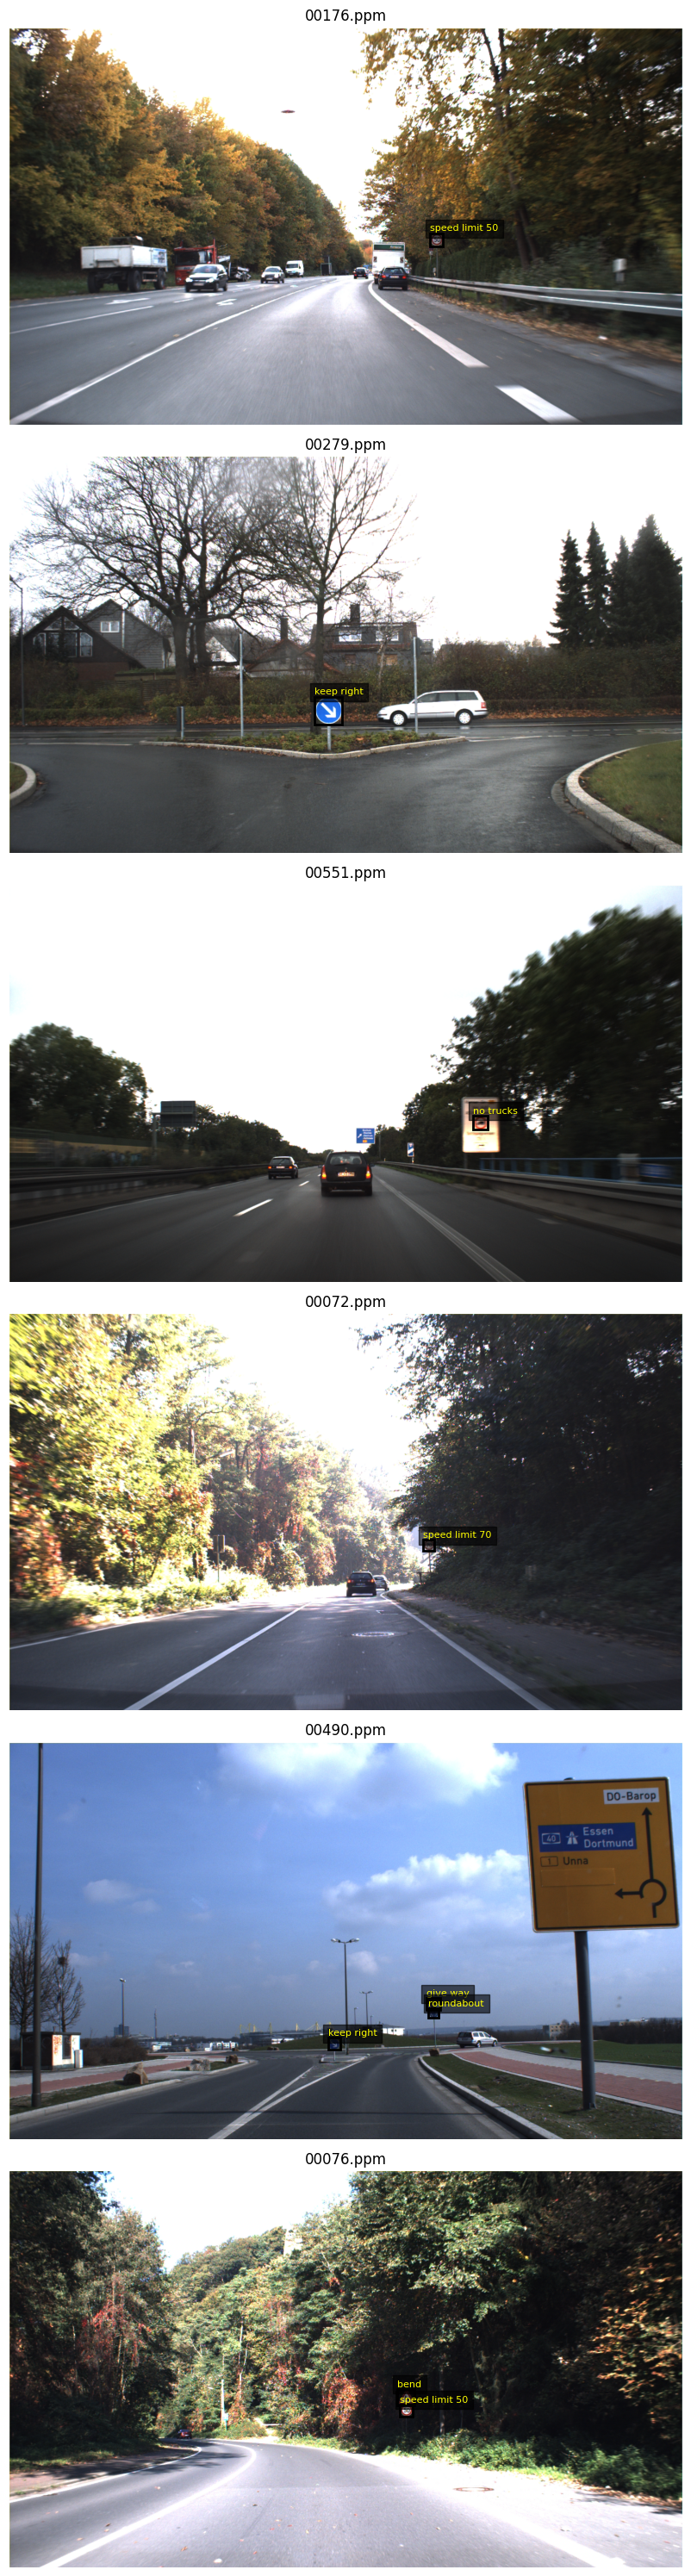

In [16]:
import matplotlib.pyplot as plt
def show_annotated_samples(frame, n=6):
    names = frame.filename.drop_duplicates().sample(min(n, frame.filename.nunique()), random_state=SEED).tolist()
    fig, axes = plt.subplots(len(names), 1, figsize=(12, 5*len(names)))
    if len(names) == 1: axes = [axes]
    for ax, name in zip(axes, names):
        rows = frame[frame.filename == name]
        img = cv2.imread(rows.iloc[0].image_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        for r in rows.itertuples():
            rect = plt.Rectangle((r.x1,r.y1), r.x2-r.x1, r.y2-r.y1, fill=False, linewidth=2)
            ax.add_patch(rect)
            ax.text(r.x1, max(0,r.y1-4), CLASS_NAMES[r.class_id], color="yellow", fontsize=8,
                    bbox=dict(facecolor="black", alpha=.6))
        ax.set_title(name); ax.axis("off")
    plt.tight_layout(); plt.show()

show_annotated_samples(annotations)

## 9. Create leakage-safe train/validation/test splits

If the downloaded benchmark provides an official train/test partition, preserve it and split only the training partition into train/validation. Set the two path variables below based on the audit. If the mirror contains only one annotated pool, this cell creates a deterministic image-level split and documents that it is **not** the official benchmark split.

Never split individual boxes independently: all boxes from one scene must stay together.

In [17]:
# This Kaggle mirror includes the official 600-image training package and
# 300 official test images, but the test package has no ground-truth gt.txt.
# Therefore create a deterministic internal holdout from ALL 600 labelled
# training-package scene files. Keep the official 300 test images for inference
# only; do not claim benchmark test mAP without their labels.

from sklearn.model_selection import train_test_split

all_scene_names = sorted(image_lookup.keys())
if len(all_scene_names) != 600:
    print(f"NOTE: expected 600 direct training scenes from the ReadMe; found {len(all_scene_names)}. Verify the mirror before continuing.")

train_names, hold_names = train_test_split(
    all_scene_names, test_size=0.30, random_state=SEED
)
val_names, test_names = train_test_split(
    hold_names, test_size=0.50, random_state=SEED
)

train_image_names = sorted(train_names)
val_image_names = sorted(val_names)
test_image_names = sorted(test_names)

train_df = annotations[annotations.filename.isin(train_image_names)].copy()
val_df = annotations[annotations.filename.isin(val_image_names)].copy()
test_df = annotations[annotations.filename.isin(test_image_names)].copy()

split_note = (
    "Deterministic image-level 70/15/15 internal split across all direct full-scene "
    "images in the official GTSDB training package. Includes unannotated negative "
    "scenes. This is not the official competition test split; the separate 300 "
    "official test images have no labels in this Kaggle mirror."
)
print(split_note)
print("Scene images:", {
    "train": len(train_image_names),
    "val": len(val_image_names),
    "internal_test": len(test_image_names)
})
print("Annotated scene images:", {
    "train": train_df.filename.nunique(),
    "val": val_df.filename.nunique(),
    "internal_test": test_df.filename.nunique()
})
assert set(train_image_names).isdisjoint(val_image_names)
assert set(train_image_names).isdisjoint(test_image_names)
assert set(val_image_names).isdisjoint(test_image_names)

Deterministic image-level 70/15/15 internal split across all direct full-scene images in the official GTSDB training package. Includes unannotated negative scenes. This is not the official competition test split; the separate 300 official test images have no labels in this Kaggle mirror.
Scene images: {'train': 420, 'val': 90, 'internal_test': 90}
Annotated scene images: {'train': 362, 'val': 72, 'internal_test': 72}


## 10. Convert annotations to YOLO format and build dataset folders

YOLO detection labels use one text file per image with rows: `class_id x_center y_center width height`, normalized to 0–1. This initial conversion includes images referenced by the annotation table. If the benchmark archive contains additional unannotated negative scenes, we will add them explicitly after confirming the image split structure.

In [24]:

from collections import defaultdict
import yaml
from PIL import Image

YOLO_ROOT = PROCESSED_DIR / "gtsdb"

def convert_split(frame, split, image_names):
    grouped = defaultdict(list)
    for r in frame.itertuples():
        grouped[r.filename].append(r)

    image_dir = YOLO_ROOT / "images" / split
    label_dir = YOLO_ROOT / "labels" / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    for name in image_names:
        src = image_lookup[name]

        # Convert every source image to lossless PNG.
        # Ultralytics does not support the original PPM format.
        with Image.open(src) as im:
            im = im.convert("RGB")
            w, h = im.size

            dst_name = f"{Path(name).stem}.png"
            im.save(image_dir / dst_name, format="PNG", optimize=True)

        # Preserve the original bounding-box coordinates and
        # normalize them using the original image dimensions.
        lines = []
        for r in grouped.get(name, []):
            xc = ((r.x1 + r.x2) / 2) / w
            yc = ((r.y1 + r.y2) / 2) / h
            bw = (r.x2 - r.x1) / w
            bh = (r.y2 - r.y1) / h

            lines.append(
                f"{r.class_id} {xc:.8f} {yc:.8f} {bw:.8f} {bh:.8f}"
            )

        # Empty label files are intentional for negative scenes.
        (label_dir / (Path(dst_name).stem + ".txt")).write_text(
            "\n".join(lines)
        )

    return len(image_names)


# Rebuild only the processed dataset.
# The original Kaggle download and annotations remain untouched.
if YOLO_ROOT.exists():
    shutil.rmtree(YOLO_ROOT)

for split in ["train", "val", "test"]:
    (YOLO_ROOT / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_ROOT / "labels" / split).mkdir(parents=True, exist_ok=True)

counts = {
    "train": convert_split(train_df, "train", train_image_names),
    "val": convert_split(val_df, "val", val_image_names),
    "test": convert_split(test_df, "test", test_image_names),
}

print("Converted full-scene image counts:", counts)

print("Image extensions:", {
    split: sorted({
        p.suffix.lower()
        for p in (YOLO_ROOT / "images" / split).iterdir()
        if p.is_file()
    })
    for split in ["train", "val", "test"]
})

print("Empty-label negative scenes:", {
    split: sum(
        not (YOLO_ROOT / "labels" / split / (Path(n).stem + ".txt"))
        .read_text().strip()
        for n in names
    )
    for split, names in [
        ("train", train_image_names),
        ("val", val_image_names),
        ("test", test_image_names),
    ]
})

Converted full-scene image counts: {'train': 420, 'val': 90, 'test': 90}
Image extensions: {'train': ['.png'], 'val': ['.png'], 'test': ['.png']}
Empty-label negative scenes: {'train': 58, 'val': 18, 'test': 18}


## 11. Write YOLO dataset configuration and validate labels

In [25]:

data_yaml = {
    "path": str(YOLO_ROOT),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(CLASS_NAMES),
    "names": list(CLASS_NAMES),
}

yaml_path = PROJECT_DIR / "gtsdb.yaml"
yaml_path.write_text(yaml.safe_dump(data_yaml, sort_keys=False))

print("YOLO dataset configuration:")
print(yaml_path.read_text())


# Image formats supported by Ultralytics YOLO.
SUPPORTED_IMAGE_EXTENSIONS = {
    ".bmp",
    ".dng",
    ".jpeg",
    ".jpg",
    ".mpo",
    ".png",
    ".tif",
    ".tiff",
    ".webp",
    ".pfm",
}


def validate_yolo_split(split):
    image_dir = YOLO_ROOT / "images" / split
    label_dir = YOLO_ROOT / "labels" / split

    problems = []

    # Confirm that both directories exist.
    if not image_dir.is_dir():
        return [f"Missing image directory: {image_dir}"]

    if not label_dir.is_dir():
        return [f"Missing label directory: {label_dir}"]

    # Collect image files only.
    image_files = sorted(
        p for p in image_dir.iterdir()
        if p.is_file()
    )

    label_files = sorted(
        p for p in label_dir.iterdir()
        if p.is_file()
    )

    # Check that the split contains images.
    if not image_files:
        problems.append(f"No images found in {image_dir}")

    # Check that every image has an Ultralytics-supported extension.
    for img_path in image_files:
        if img_path.suffix.lower() not in SUPPORTED_IMAGE_EXTENSIONS:
            problems.append(
                f"Unsupported image extension: {img_path.name}"
            )

    # Check that every image has a corresponding label file.
    expected_label_names = {
        img_path.stem + ".txt"
        for img_path in image_files
    }

    actual_label_names = {
        label_path.name
        for label_path in label_files
    }

    for missing_label in sorted(expected_label_names - actual_label_names):
        problems.append(
            f"Missing label file: {label_dir / missing_label}"
        )

    # Check for unexpected label files.
    for extra_label in sorted(actual_label_names - expected_label_names):
        problems.append(
            f"Label file has no matching image: {extra_label}"
        )

    # Validate every YOLO annotation.
    for img_path in image_files:
        label_path = label_dir / (img_path.stem + ".txt")

        if not label_path.exists():
            continue

        for line_no, line in enumerate(
            label_path.read_text().splitlines(), 1
        ):
            vals = line.split()

            if len(vals) != 5:
                problems.append(
                    f"{label_path}:{line_no}: expected 5 values"
                )
                continue

            try:
                cls, xc, yc, bw, bh = map(float, vals)
            except ValueError:
                problems.append(
                    f"{label_path}:{line_no}: non-numeric annotation values"
                )
                continue

            # Validate class ID.
            if (
                not cls.is_integer()
                or not (0 <= int(cls) < len(CLASS_NAMES))
            ):
                problems.append(
                    f"{label_path}:{line_no}: invalid class {cls}"
                )

            # Validate normalized bounding-box coordinates.
            if not all(
                0 <= v <= 1
                for v in [xc, yc, bw, bh]
            ) or bw <= 0 or bh <= 0:
                problems.append(
                    f"{label_path}:{line_no}: invalid normalized box"
                )

    return problems


# Validate all three dataset splits.
split_counts = {}

for split in ["train", "val", "test"]:
    image_dir = YOLO_ROOT / "images" / split
    label_dir = YOLO_ROOT / "labels" / split

    image_count = sum(
        1 for p in image_dir.iterdir() if p.is_file()
    ) if image_dir.is_dir() else 0

    label_count = sum(
        1 for p in label_dir.iterdir() if p.is_file()
    ) if label_dir.is_dir() else 0

    split_counts[split] = {
        "images": image_count,
        "labels": label_count,
    }

    issues = validate_yolo_split(split)

    print(f"\n{split.upper()} SPLIT")
    print("Images:", image_count)
    print("Label files:", label_count)
    print("Issues:", len(issues))

    if issues:
        print("First validation issues:")
        for issue in issues[:20]:
            print(" -", issue)

        raise ValueError(
            f"YOLO validation failed for the {split} split."
        )

    extensions = sorted({
        p.suffix.lower()
        for p in image_dir.iterdir()
        if p.is_file()
    })

    print("Image extensions:", extensions)


# Confirm expected split sizes.
expected_counts = {
    "train": 420,
    "val": 90,
    "test": 90,
}

for split, expected in expected_counts.items():
    actual = split_counts[split]["images"]

    if actual != expected:
        raise ValueError(
            f"{split} split expected {expected} images, found {actual}."
        )

    if split_counts[split]["labels"] != expected:
        raise ValueError(
            f"{split} split expected {expected} label files, "
            f"found {split_counts[split]['labels']}."
        )


print("\n" + "=" * 55)
print("DATASET CONVERSION AND VALIDATION PASSED")
print("=" * 55)
print("Total images:", sum(v["images"] for v in split_counts.values()))
print("Total label files:", sum(v["labels"] for v in split_counts.values()))
print("Expected distribution: train=420, val=90, test=90")
print("All images use Ultralytics-supported formats.")
print("All images have matching label files.")
print("All annotation files passed validation.")

YOLO dataset configuration:
path: /content/drive/MyDrive/traffic-sign-detection/data/processed/gtsdb
train: images/train
val: images/val
test: images/test
nc: 43
names:
- speed limit 20
- speed limit 30
- speed limit 50
- speed limit 60
- speed limit 70
- speed limit 80
- restriction ends 80
- speed limit 100
- speed limit 120
- no overtaking
- no overtaking trucks
- priority at next intersection
- priority road
- give way
- stop
- no traffic both ways
- no trucks
- no entry
- danger
- bend left
- bend right
- bend
- uneven road
- slippery road
- road narrows
- construction
- traffic signal
- pedestrian crossing
- school crossing
- cycles crossing
- snow
- animals
- restriction ends
- go right
- go left
- go straight
- go right or straight
- go left or straight
- keep right
- keep left
- roundabout
- restriction ends overtaking
- restriction ends overtaking trucks


TRAIN SPLIT
Images: 420
Label files: 420
Issues: 0
Image extensions: ['.png']

VAL SPLIT
Images: 90
Label files: 90
Issue

## 12. Train YOLOv8

Start with YOLOv8n as a lightweight baseline. For small signs, image size 960 can help preserve detail but increases memory and inference cost. If GPU memory is insufficient, reduce `IMGSZ` to 640 or `BATCH` to 8. Checkpoints and plots are copied to Drive after training.

In [4]:
# TRAIN YOLOv8n ON THE VALIDATED GTSDB DATASET
import time
import torch
import yaml
from datetime import datetime
from pathlib import Path
from ultralytics import YOLO

# Define paths locally in case the runtime was restarted
PROJECT_DIR = Path("/content/drive/MyDrive/traffic-sign-detection")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
YOLO_ROOT = PROCESSED_DIR / "gtsdb"
yaml_path = PROJECT_DIR / "gtsdb.yaml"
RUNS_DIR = PROJECT_DIR / "runs"
SEED = 42

# 1. Confirm that the dataset configuration exists.
if not yaml_path.exists():
    raise FileNotFoundError(f"Dataset YAML not found: {yaml_path}")

with open(yaml_path, "r") as f:
    dataset_config = yaml.safe_load(f)

if dataset_config.get("nc") != 43:
    raise ValueError(f"Expected 43 classes, found {dataset_config.get('nc')}.")

if len(dataset_config.get("names", [])) != 43:
    raise ValueError("Dataset YAML must contain exactly 43 class names.")

# 2. Verify that all three converted splits are visible and contain PNGs.
expected_counts = {
    "train": 420,
    "val": 90,
    "test": 90,
}

for split, expected_count in expected_counts.items():
    image_dir = YOLO_ROOT / "images" / split
    label_dir = YOLO_ROOT / "labels" / split

    if not image_dir.is_dir() or not label_dir.is_dir():
        raise FileNotFoundError(f"Missing image or label directory for {split}.")

    image_files = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() == ".png"
    ]
    label_files = list(label_dir.glob("*.txt"))

    print(
        f"{split.upper()}: "
        f"{len(image_files)} PNG images | "
        f"{len(label_files)} label files"
    )

    if len(image_files) != expected_count:
        raise ValueError(
            f"{split}: expected {expected_count} PNG images, "
            f"found {len(image_files)}."
        )

    if len(label_files) != expected_count:
        raise ValueError(
            f"{split}: expected {expected_count} label files, "
            f"found {len(label_files)}."
        )

    if len(image_files) != len(label_files):
        raise ValueError(f"{split}: image/label counts do not match.")

print("\nDataset structure checks passed.")

# 3. Refresh the training image directory listing.
train_img_path = YOLO_ROOT / "images" / "train"

print(
    "\nTraining images visible to Python:",
    len(list(train_img_path.glob("*.png")))
)

# 4. Remove stale Ultralytics cache files.
deleted_caches = []

for cache_file in YOLO_ROOT.rglob("*.cache"):
    cache_file.unlink()
    deleted_caches.append(str(cache_file))

if deleted_caches:
    print("\nRemoved stale cache files:")
    for cache in deleted_caches:
        print(cache)
else:
    print("\nNo stale YOLO cache files found.")

# 5. Configure training.
MODEL_NAME = "yolov8n.pt"
IMGSZ = 960
EPOCHS = 100
BATCH = 8
PATIENCE = 20

DEVICE = 0 if torch.cuda.is_available() else "cpu"
USE_AMP = torch.cuda.is_available()

# Automatically append timestamp to prevent directory conflicts
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_NAME = f"gtsdb_yolov8n_png_{timestamp}"
TRAIN_RUN_DIR = RUNS_DIR / RUN_NAME

print("\nTraining configuration")
print("----------------------")
print("Model:", MODEL_NAME)
print("Image size:", IMGSZ)
print("Maximum epochs:", EPOCHS)
print("Batch size:", BATCH)
print("Early-stopping patience:", PATIENCE)
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Automatic mixed precision:", USE_AMP)
print("Dataset YAML:", yaml_path)
print("Training output:", TRAIN_RUN_DIR)

# 6. Initialize the pretrained YOLOv8n model.
model = YOLO(MODEL_NAME)

# 7. Train.
training_start = time.perf_counter()

train_results = model.train(
    data=str(yaml_path),
    imgsz=IMGSZ,
    epochs=EPOCHS,
    batch=BATCH,
    patience=PATIENCE,
    device=DEVICE,
    workers=2,
    seed=SEED,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=False,
    plots=True,
    cache=False,
    pretrained=True,
    amp=USE_AMP,
)

training_elapsed = time.perf_counter() - training_start

# 8. Verify the training artifacts.
BEST_WEIGHTS = TRAIN_RUN_DIR / "weights" / "best.pt"
LAST_WEIGHTS = TRAIN_RUN_DIR / "weights" / "last.pt"
RESULTS_CSV = TRAIN_RUN_DIR / "results.csv"

if not BEST_WEIGHTS.is_file():
    raise FileNotFoundError(
        f"Training did not produce the expected best checkpoint: {BEST_WEIGHTS}"
    )

if not LAST_WEIGHTS.is_file():
    raise FileNotFoundError(
        f"Training did not produce the expected last checkpoint: {LAST_WEIGHTS}"
    )

print("\n" + "=" * 60)
print("TRAINING COMPLETED — CHECKPOINTS VERIFIED")
print("=" * 60)
print("Best checkpoint:", BEST_WEIGHTS)
print("Last checkpoint:", LAST_WEIGHTS)
print("Training results CSV:", RESULTS_CSV if RESULTS_CSV.exists() else "Not found")
print("Elapsed minutes:", round(training_elapsed / 60, 2))
print("Training output directory:", TRAIN_RUN_DIR)

TRAIN: 420 PNG images | 420 label files
VAL: 90 PNG images | 90 label files
TEST: 90 PNG images | 90 label files

Dataset structure checks passed.

Training images visible to Python: 420

Removed stale cache files:
/content/drive/MyDrive/traffic-sign-detection/data/processed/gtsdb/labels/train.cache
/content/drive/MyDrive/traffic-sign-detection/data/processed/gtsdb/labels/val.cache

Training configuration
----------------------
Model: yolov8n.pt
Image size: 960
Maximum epochs: 100
Batch size: 8
Early-stopping patience: 20
Device: Tesla T4
Automatic mixed precision: True
Dataset YAML: /content/drive/MyDrive/traffic-sign-detection/gtsdb.yaml
Training output: /content/drive/MyDrive/traffic-sign-detection/runs/gtsdb_yolov8n_png_20261115_093754
Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None

In [6]:
# Inspect the duplicate annotation reported by Ultralytics.
import pandas as pd
from pathlib import Path

# Define paths locally in case the runtime was restarted
PROJECT_DIR = Path("/content/drive/MyDrive/traffic-sign-detection")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
YOLO_ROOT = PROCESSED_DIR / "gtsdb"

duplicate_image = "00340.png"
duplicate_label = YOLO_ROOT / "labels" / "val" / "00340.txt"

print("Image:", duplicate_image)
print("Label file:", duplicate_label)

if not duplicate_label.exists():
    raise FileNotFoundError(duplicate_label)

label_lines = [
    line.strip()
    for line in duplicate_label.read_text().splitlines()
    if line.strip()
]

print("\nOriginal YOLO label rows:")
for line in label_lines:
    print(line)

print("\nExact duplicate rows:")
seen = set()
duplicates = []

for line in label_lines:
    if line in seen:
        duplicates.append(line)
    seen.add(line)

print(duplicates if duplicates else "No exact duplicate rows.")

# Re-parse or load the native annotations if the variable 'annotations' is missing
if 'annotations' not in globals():
    print("\nVariable 'annotations' not found in memory. Re-parsing from source file...")
    TRAIN_PACKAGE_DIR = PROJECT_DIR / "data" / "raw" / "kaggle_download" / "TrainIJCNN2013" / "TrainIJCNN2013"
    ANNOTATION_FILE = TRAIN_PACKAGE_DIR / "gt.txt"

    if not ANNOTATION_FILE.exists():
        raise FileNotFoundError(f"Expected official training annotations at {ANNOTATION_FILE}")

    rows = []
    with open(ANNOTATION_FILE, "r", encoding="utf-8-sig") as f:
        for line_no, raw in enumerate(f, 1):
            line = raw.strip()
            if not line or line.startswith("#"):
                continue
            parts = [x.strip() for x in line.split(";")]
            if len(parts) != 6:
                if line_no == 1 and any("filename" in x.lower() for x in parts):
                    continue
                raise ValueError(f"Line {line_no}: expected 6 semicolon-separated fields, got {len(parts)}: {line}")
            try:
                filename = parts[0]
                x1, y1, x2, y2, cls = map(int, parts[1:])
            except ValueError:
                if line_no == 1:
                    continue
                raise
            rows.append({"filename": filename, "x1": x1, "y1": y1, "x2": x2, "y2": y2, "class_id": cls})
    annotations = pd.DataFrame(rows)

native_rows = annotations[
    annotations["filename"] == duplicate_image.replace(".png", ".ppm")
]

print("\nOriginal native annotations:")
display(native_rows)

print("\nNumber of native annotation rows:", len(native_rows))

Image: 00340.png
Label file: /content/drive/MyDrive/traffic-sign-detection/data/processed/gtsdb/labels/val/00340.txt

Original YOLO label rows:
14 0.61691176 0.69375000 0.01764706 0.03000000
33 0.61727941 0.66687500 0.01838235 0.03125000
14 0.61691176 0.69375000 0.01764706 0.03000000

Exact duplicate rows:
['14 0.61691176 0.69375000 0.01764706 0.03000000']

Variable 'annotations' not found in memory. Re-parsing from source file...

Original native annotations:


,filename,x1,y1,x2,y2,class_id
532,00340.ppm,827,543,851,567,14
533,00340.ppm,827,521,852,546,33
534,00340.ppm,827,543,851,567,14



Number of native annotation rows: 3


## 13. Evaluate on validation and the internal held-out test split

Use validation results for model selection and confidence-threshold tuning. Evaluate the internal held-out split once for final reporting. This Kaggle mirror does not include labels for the official 300-image competition test package, so do not describe these internal metrics as official benchmark test scores.

In [ ]:
best_model = YOLO(str(BEST_WEIGHTS))
val_metrics = best_model.val(data=str(yaml_path), split="val", imgsz=IMGSZ, device=DEVICE, plots=True)
test_metrics = best_model.val(data=str(yaml_path), split="test", imgsz=IMGSZ, device=DEVICE, plots=True)

def metric_summary(metrics):
    box=getattr(metrics,"box",None)
    if box is None: return {}
    return {
        "precision": float(box.mp),
        "recall": float(box.mr),
        "mAP50": float(box.map50),
        "mAP50-95": float(box.map),
    }
evaluation = {"validation":metric_summary(val_metrics),"test":metric_summary(test_metrics)}
print(json.dumps(evaluation,indent=2))
(PROJECT_DIR/"evaluation_metrics.json").write_text(json.dumps(evaluation,indent=2))

## 14. Review training curves and predictions

Look for overfitting, poor recall on small signs, class imbalance and localization errors. Do not rely on one aggregate metric alone.

In [ ]:
from IPython.display import display, Image as IPyImage
results_dir=RUNS_DIR/"gtsdb_yolov8n"
for filename in ["results.png","confusion_matrix.png","PR_curve.png","F1_curve.png"]:
    p=results_dir/filename
    if p.exists():
        print(filename); display(IPyImage(filename=str(p)))
preds=best_model.predict(source=str(YOLO_ROOT/"images"/"test"), imgsz=IMGSZ, conf=0.25, device=DEVICE, save=True,
                         project=str(RUNS_DIR), name="test_predictions", exist_ok=True)
print("Prediction output:", RUNS_DIR/"test_predictions")

## 15. Benchmark inference latency and FPS

This reports model inference throughput on the current Colab runtime, not end-to-end video throughput. Warm-up is excluded; timings use repeated single-image inference. Record GPU/CPU, image size, batch size and runtime because FPS is hardware-dependent.

In [ ]:
import statistics
test_images=list((YOLO_ROOT/"images"/"test").glob("*"))
if not test_images: raise RuntimeError("No test images available.")
sample_paths=test_images[:min(100,len(test_images))]
for p in sample_paths[:5]:
    best_model.predict(source=str(p), imgsz=IMGSZ, conf=0.25, device=DEVICE, verbose=False)
latencies=[]
for p in sample_paths:
    t0=time.perf_counter()
    best_model.predict(source=str(p), imgsz=IMGSZ, conf=0.25, device=DEVICE, verbose=False)
    latencies.append((time.perf_counter()-t0)*1000)
mean_ms=float(np.mean(latencies))
fps=1000/mean_ms
speed_report={
    "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "imgsz": IMGSZ, "batch_size":1, "images_timed":len(latencies),
    "mean_latency_ms":mean_ms, "median_latency_ms":float(np.median(latencies)),
    "p95_latency_ms":float(np.percentile(latencies,95)), "approx_fps":fps,
    "timing_scope":"single-image predict call; includes preprocessing/postprocessing overhead; excludes file decode variance and video display"
}
print(json.dumps(speed_report,indent=2))
(PROJECT_DIR/"speed_benchmark.json").write_text(json.dumps(speed_report,indent=2))

## 16. Export to ONNX and verify runtime inference

Export from the best PyTorch checkpoint. Then load the ONNX model with ONNX Runtime and compare basic output shape/execution. The exported graph's raw outputs are not directly comparable to postprocessed YOLO detections without applying the same decode/NMS pipeline, so this cell verifies successful inference rather than claiming numerical parity.

In [ ]:
onnx_path = Path(best_model.export(format="onnx", imgsz=IMGSZ, opset=12, simplify=True))
drive_onnx = EXPORT_DIR/"best.onnx"
shutil.copy2(onnx_path, drive_onnx)
import onnx
onnx_model=onnx.load(str(drive_onnx))
onnx.checker.check_model(onnx_model)
import onnxruntime as ort
providers=["CUDAExecutionProvider","CPUExecutionProvider"] if torch.cuda.is_available() else ["CPUExecutionProvider"]
session=ort.InferenceSession(str(drive_onnx),providers=providers)
input_meta=session.get_inputs()[0]
dummy=np.zeros(input_meta.shape,dtype=np.float32)
outputs=session.run(None,{input_meta.name:dummy})
print("ONNX validated:", drive_onnx)
print("Providers:",session.get_providers())
print("Input:",input_meta.name,input_meta.shape)
print("Output shapes:",[x.shape for x in outputs])

## 17. Recorded-road-video inference (webcam alternative)

You do not need a physical webcam. Upload a road-driving video that you have permission to use, or use a suitably licensed/public sample and record its source and licence. This is **prerecorded-video inference**, not live webcam testing.

The output video is saved to Drive. If the video is very large, trim it before processing.

In [ ]:
from google.colab import files
uploaded_video = files.upload()
video_names=[n for n in uploaded_video if Path(n).suffix.lower() in {".mp4",".avi",".mov",".mkv"}]
if not video_names:
    raise FileNotFoundError("Upload a supported road video (.mp4, .avi, .mov or .mkv).")
VIDEO_SOURCE=Path(video_names[0])
video_out=VIDEO_DIR/f"{VIDEO_SOURCE.stem}_detections.mp4"

CONFIDENCE_THRESHOLD=0.25
cap=cv2.VideoCapture(str(VIDEO_SOURCE))
if not cap.isOpened(): raise RuntimeError("Could not open uploaded video.")
fps_in=cap.get(cv2.CAP_PROP_FPS) or 25.0
width=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); height=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total=int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
writer=cv2.VideoWriter(str(video_out),cv2.VideoWriter_fourcc(*"mp4v"),fps_in,(width,height))
frame_count=0
t_start=time.perf_counter()
while True:
    ok,frame=cap.read()
    if not ok: break
    result=best_model.predict(frame,conf=CONFIDENCE_THRESHOLD,imgsz=IMGSZ,device=DEVICE,verbose=False)[0]
    annotated=result.plot()
    writer.write(annotated)
    frame_count+=1
cap.release(); writer.release()
elapsed=time.perf_counter()-t_start
print("Saved:",video_out)
print("Frames:",frame_count,"Elapsed seconds:",round(elapsed,2))
print("End-to-end video processing FPS:",round(frame_count/elapsed,2) if elapsed else None)

## 18. Confidence-threshold review

The confidence threshold controls the precision/recall trade-off. Use validation data to compare thresholds; do not tune against the held-out test set. This quick sweep logs validation mAP/precision/recall for selected confidence settings.

In [ ]:
threshold_rows=[]
for conf in [0.10,0.15,0.20,0.25,0.30,0.40,0.50]:
    m=best_model.val(data=str(yaml_path),split="val",imgsz=IMGSZ,device=DEVICE,conf=conf,plots=False,verbose=False)
    threshold_rows.append({"confidence":conf,**metric_summary(m)})
threshold_df=pd.DataFrame(threshold_rows)
display(threshold_df)
threshold_df.to_csv(PROJECT_DIR/"confidence_threshold_validation.csv",index=False)

## 19. Save a reproducibility report

This collects the dataset split note, class mapping, package versions, training settings, evaluation metrics and measured speed. Review and supplement the dataset source/licence and any deviations before publishing results.

In [ ]:
import importlib.metadata as metadata
report={
    "project":"GTSDB full-scene traffic sign detection",
    "dataset_source":KAGGLE_DATASET if USE_KAGGLE else "Manually supplied official archive",
    "split_note":split_note,
    "seed":SEED,
    "classes":list(CLASS_NAMES),
    "images_per_split":{k:int(v.filename.nunique()) for k,v in {"train":train_df,"val":val_df,"test":test_df}.items()},
    "training":{"model":MODEL_NAME,"imgsz":IMGSZ,"epochs_requested":EPOCHS,"batch":BATCH,"device":DEVICE},
    "evaluation":evaluation,
    "speed":speed_report,
    "versions":{p:metadata.version(p) for p in ["ultralytics","torch","opencv-python-headless","onnxruntime"] if any(d.metadata["Name"].lower()==p.lower() for d in metadata.distributions())},
    "video_inference":{"input":str(VIDEO_SOURCE),"output":str(video_out),"confidence_threshold":CONFIDENCE_THRESHOLD},
    "limitations":[
        "Report whether the dataset mirror is complete and whether official benchmark splits were preserved.",
        "FPS depends on runtime hardware, image size and measurement scope.",
        "Recorded-video inference is not physical webcam validation."
    ]
}
report_path=PROJECT_DIR/"task_08_results_report.json"
report_path.write_text(json.dumps(report,indent=2))
print("Report saved:",report_path)
print(json.dumps(report,indent=2))

## 20. Final checklist and portfolio handoff

Before marking Task 8 complete:

- [ ] Confirm dataset source, completeness and licence.
- [ ] Verify the class-ID mapping against the supplied documentation.
- [ ] Inspect annotated full-scene samples and label quality.
- [ ] Confirm no image overlap between train, validation and internal test.
- [ ] Clearly identify the 70/15/15 split as an internal split, not the official competition test split.
- [ ] Save best weights and ONNX export in Drive or a model registry (not Git).
- [ ] Record precision, recall, mAP50, mAP50-95 and per-class results.
- [ ] Record hardware, input size, latency and FPS methodology.
- [ ] Save prediction examples and the annotated prerecorded video.
- [ ] Update the repository README with measured results only.
- [ ] Run project tests and review the GitHub PR before merging.

**Next collaboration step:** the dataset audit is complete and the notebook now contains the verified training annotation path, all 43 class names, and a leakage-safe split across the full-scene training images (including negative scenes). Reopen the updated notebook, restart the Colab runtime, then run Sections 0–11 in order. Stop after Section 11 and share the validation output before starting model training. The 300 official test images are kept separate because this mirror does not provide their labels. Gemini can help explain/debug a cell, and I can review each output with you.